# LAB 3B: Multi-Layer Perceptron

## Overview
This notebook is organized into clear labeled sections to make the code easier to follow without changing the original logic.

### Section guide
1. Imports and setup
2. Hidden-layer logic
3. Training and evaluation
4. Curves and plotting


In [1]:
import os
import random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

## Part A: Hidden-layer logic


In [2]:
def step(z):
    return np.where(z >= 0, 1.0, 0.0)

# Manual Weights
W_hidden = np.array([[ 20.0, -20.0], [ 20.0, -20.0]])
b_hidden = np.array([-10.0,  30.0])

def mlp_manual(x, W_out, b_out):
    h = step(np.dot(x, W_hidden) + b_hidden)
    return step(np.dot(h, W_out) + b_out)

W_xor, b_xor = np.array([ 20.0,  20.0]), -30.0
W_xnor, b_xnor = np.array([-20.0, -20.0]),  30.0
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

print("XOR (manual weights):", [int(mlp_manual(x, W_xor, b_xor)) for x in X_gate])
print("XNOR (manual weights):", [int(mlp_manual(x, W_xnor, b_xnor)) for x in X_gate])

# Backpropagation Training
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def train_mlp(X, t, hidden=5, lr=0.1, epochs=10000, seed=0):
    rng = np.random.default_rng(seed)
    W1 = rng.uniform(size=(2, hidden))
    b1 = rng.uniform(size=(1, hidden))
    W2 = rng.uniform(size=(hidden, 1))
    b2 = rng.uniform(size=(1, 1))
    for _ in range(epochs):
        h = sigmoid(X @ W1 + b1)
        y = sigmoid(h @ W2 + b2)
        d_out = (t - y) * y * (1 - y)
        d_hid = (d_out @ W2.T) * h * (1 - h)
        W2 += lr * h.T @ d_out
        b2 += lr * d_out.sum(0, keepdims=True)
        W1 += lr * X.T @ d_hid
        b1 += lr * d_hid.sum(0, keepdims=True)
    h = sigmoid(X @ W1 + b1)
    return sigmoid(h @ W2 + b2)

for name, t in [("XOR", [[0], [1], [1], [0]]), ("XNOR", [[1], [0], [0], [1]])]:
    t_arr = np.array(t, dtype=float)
    y_out = train_mlp(X_gate, t_arr, hidden=5)
    print(f"\n{name} learned (5 hidden sigmoid neurons, lr=0.1, 10000 epochs)")
    for x_val, yy in zip(X_gate, y_out):
        print(f"  {x_val[0]} {name} {x_val[1]} -> raw output {yy[0]:.4f} -> class {int(yy[0] >= 0.5)}")

XOR (manual weights): [0, 1, 1, 0]
XNOR (manual weights): [1, 0, 0, 1]

XOR learned (5 hidden sigmoid neurons, lr=0.1, 10000 epochs)
  0 XOR 0 -> raw output 0.0507 -> class 0
  0 XOR 1 -> raw output 0.9454 -> class 1
  1 XOR 0 -> raw output 0.9546 -> class 1
  1 XOR 1 -> raw output 0.0534 -> class 0

XNOR learned (5 hidden sigmoid neurons, lr=0.1, 10000 epochs)
  0 XNOR 0 -> raw output 0.9640 -> class 1
  0 XNOR 1 -> raw output 0.0531 -> class 0
  1 XNOR 0 -> raw output 0.0353 -> class 0
  1 XNOR 1 -> raw output 0.9475 -> class 1


## Part B: Training and evaluation


## Training curves


In [3]:
def set_seed(s=42):
    random.seed(s)
    np.random.seed(s)
    tf.random.set_seed(s)

iris = load_iris()
X, y = iris.data, iris.target
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

def build(hidden=(16, 8), lr=0.01, l2=0.0, dropout=0.0):
    m = keras.Sequential([layers.Input(shape=(4,))])
    for units in hidden:
        m.add(layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(l2) if l2 else None))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(3, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def run(epochs=100, batch=16, **kw):
    set_seed(42)
    m = build(**kw)
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch, verbose=0)
    test_loss, test_acc = m.evaluate(X_test, y_test, verbose=0)
    return m, h, test_acc

model, hist, test_acc = run()
model.summary()
print(f"\nBaseline final train acc = {hist.history['accuracy'][-1]:.4f} | val acc = {hist.history['val_accuracy'][-1]:.4f} | test acc = {test_acc:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 731 (2.86 KB)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 488 (1.91 KB)


Baseline final train acc = 0.9778 | val acc = 0.9333 | test acc = 0.9333


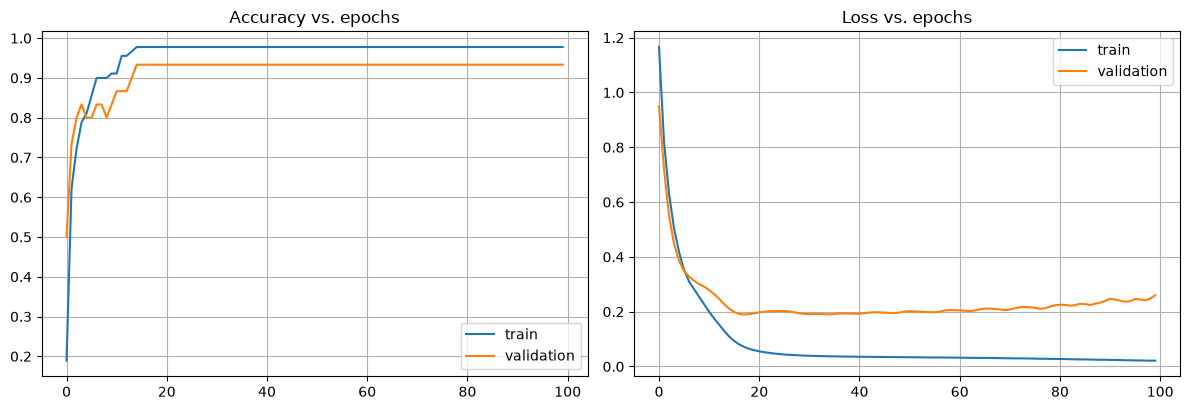


Classification report (test set):
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30


--- Regularization comparison (64,64 architecture, 200 epochs) ---
No regularization      | train acc: 1.0000 | val acc: 0.9333 | test acc: 0.9333


In [ ]:
# Curves Plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(hist.history["accuracy"], label="train")
ax[0].plot(hist.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy vs. epochs")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(hist.history["loss"], label="train")
ax[1].plot(hist.history["val_loss"], label="validation")
ax[1].set_title("Loss vs. epochs")
ax[1].legend()
ax[1].grid(True)
plt.tight_layout()
plt.show()

# Evaluation
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print("\nClassification report (test set):")
print(classification_report(y_test, y_pred, target_names=iris.target_names, digits=3))

# Regularization Comparison
print("\n--- Regularization comparison (64,64 architecture, 200 epochs) ---")
for label, kw in [("No regularization", {}), ("L2 (0.01)", dict(l2=0.01)), ("Dropout (0.3)", dict(dropout=0.3)), ("L2 + Dropout", dict(l2=0.01, dropout=0.3))]:
    _, h, ta = run(epochs=200, hidden=(64, 64), **kw)
    tr, va = h.history["accuracy"][-1], h.history["val_accuracy"][-1]
    print(f"{label:22s} | train acc: {tr:.4f} | val acc: {va:.4f} | test acc: {ta:.4f}")